## 0. Instalacja zależności

In [ ]:
!pip install torch torchvision matplotlib --quiet

## 1. Import bibliotek i konfiguracja

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import copy

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch: {torch.__version__} | urządzenie: {device}")

PyTorch: 2.11.0+cu130 | urządzenie: cuda


## 2. Dane: FashionMNIST z augmentacją i bez

In [ ]:
mean, std = 0.2860, 0.3530

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_tf_plain = test_tf

train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_plain = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=train_tf_plain
)
train_aug = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=train_tf_aug
)
test_ds = torchvision.datasets.FashionMNIST(
    "./data", train=False, download=True, transform=test_tf
)
classes = test_ds.classes

print(f"Trening: {len(train_plain)} | Test: {len(test_ds)}")


100%|██████████| 26.4M/26.4M [00:01<00:00, 14.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.83MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.3MB/s]

Trening: 60000 | Test: 10000


## 3. Podział na trening/walidację (stratyfikowany 50k/10k)

In [ ]:
g = torch.Generator().manual_seed(0)
targets = train_plain.targets

val_idx, tr_idx = [], []
for c in range(10):
    idx = (targets == c).nonzero(as_tuple=True)[0]
    idx = idx[torch.randperm(len(idx), generator=g)]
    val_idx += idx[:1000].tolist()
    tr_idx += idx[1000:].tolist()

train_ds_plain = Subset(train_plain, tr_idx)
train_ds_aug = Subset(train_aug, tr_idx)
val_ds = Subset(train_plain, val_idx)
train_eval_ds = Subset(train_plain, tr_idx)

train_dl_plain = DataLoader(train_ds_plain, batch_size=128, shuffle=True)
train_dl_aug = DataLoader(train_ds_aug, batch_size=128, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=256, shuffle=False)
train_eval_dl = DataLoader(train_eval_ds, batch_size=256, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)

print(f"Podział - Trening: {len(train_ds_plain)} | Walidacja: {len(val_ds)}")


Podział - Trening: 50000 | Walidacja: 10000


## 4. Model MLP z przełącznikami

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10,
                 use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

print("\nStruktura modelu MLP:")
print(MLP(use_bn=True, p_drop=0.3))



Struktura modelu MLP:
MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 5. Funkcje pomocnicze

In [ ]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total


def run_training(model, train_dl, val_dl, epochs=12, lr=1e-3,
                 weight_decay=0.0, optimizer="adam", use_scheduler=False,
                 patience=None, verbose=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    # Wybór optymalizatora
    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                              weight_decay=weight_decay)

    # Scheduler
    sched = torch.optim.lr_scheduler.StepLR(
        opt, step_size=max(1, epochs//3), gamma=0.5
    ) if use_scheduler else None

    # Historia
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    n = len(train_dl.dataset)

    # Early stopping
    best_loss, best_state, best_epoch, bad = float("inf"), None, 0, 0

    for epoch in range(1, epochs+1):
        model.train()
        run = 0.0

        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item() * yb.numel()

        if sched:
            sched.step()

        # Ewaluacja
        tr = run / n
        vl, va = evaluate(model, val_dl)

        hist["train_loss"].append(tr)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)

        if verbose:
            print(f"Epoka {epoch:2d} | trening {tr:.3f} | val {vl:.3f} | acc {va*100:.2f}%")

        # Early stopping
        if patience is not None:
            if vl < best_loss - 1e-4:
                best_loss, best_epoch, bad = vl, epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                bad += 1
            if bad >= patience:
                if verbose:
                    print(f"Early stopping: brak poprawy od {patience} epok")
                break

    # Przywrócenie najlepszych wag
    if patience is not None and best_state is not None:
        model.load_state_dict(best_state)
        if verbose:
            print(f"Przywrócono wagi z epoki {best_epoch} (val_loss {best_loss:.3f})")

    return hist


def plot_learning_curves(histories, names, colors):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    for name, h, c in zip(names, histories, colors):
        ax1.plot(h["train_loss"], "--", color=c, label=f"{name} — trening")
        ax1.plot(h["val_loss"], "-", color=c, label=f"{name} — walidacja")
        ax2.plot([a*100 for a in h["val_acc"]], color=c, label=name)

    ax1.set_xlabel("epoka")
    ax1.set_ylabel("strata")
    ax1.legend(fontsize=8)
    ax1.set_title("Krzywe straty (trenowanie vs walidacja)")
    ax1.grid(True, alpha=0.3)

    ax2.set_xlabel("epoka")
    ax2.set_ylabel("accuracy [%]")
    ax2.legend()
    ax2.set_title("Accuracy na walidacji")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def compute_generalization_gap(model, train_eval_dl, val_dl):
    train_eval_loss, _ = evaluate(model, train_eval_dl)
    val_loss, _ = evaluate(model, val_dl)
    return val_loss - train_eval_loss

# EKSPERYMENTY


EKSPERYMENT 1: BASELINE (bez regularyzacji)
Epoka  1 | trening 0.503 | val 0.384 | acc 86.31%
Epoka  2 | trening 0.360 | val 0.340 | acc 87.50%
Epoka  3 | trening 0.320 | val 0.333 | acc 87.80%
Epoka  4 | trening 0.295 | val 0.320 | acc 88.36%
Epoka  5 | trening 0.273 | val 0.322 | acc 88.40%
Epoka  6 | trening 0.255 | val 0.358 | acc 87.33%
Epoka  7 | trening 0.244 | val 0.325 | acc 87.90%
Epoka  8 | trening 0.229 | val 0.326 | acc 88.36%
Epoka  9 | trening 0.215 | val 0.297 | acc 89.31%
Epoka 10 | trening 0.204 | val 0.306 | acc 89.16%
Epoka 11 | trening 0.189 | val 0.320 | acc 88.86%
Epoka 12 | trening 0.182 | val 0.321 | acc 89.63%

Luka generalizacji (baseline): 0.1535

EKSPERYMENT 2a: TYLKO AUGMENTACJA
Epoka  1 | trening 0.857 | val 0.642 | acc 74.95%
Epoka  2 | trening 0.649 | val 0.573 | acc 78.63%
Epoka  3 | trening 0.595 | val 0.539 | acc 79.86%
Epoka  4 | trening 0.563 | val 0.524 | acc 80.67%
Epoka  5 | trening 0.541 | val 0.488 | acc 81.99%
Epoka  6 | trening 0.523 | val 

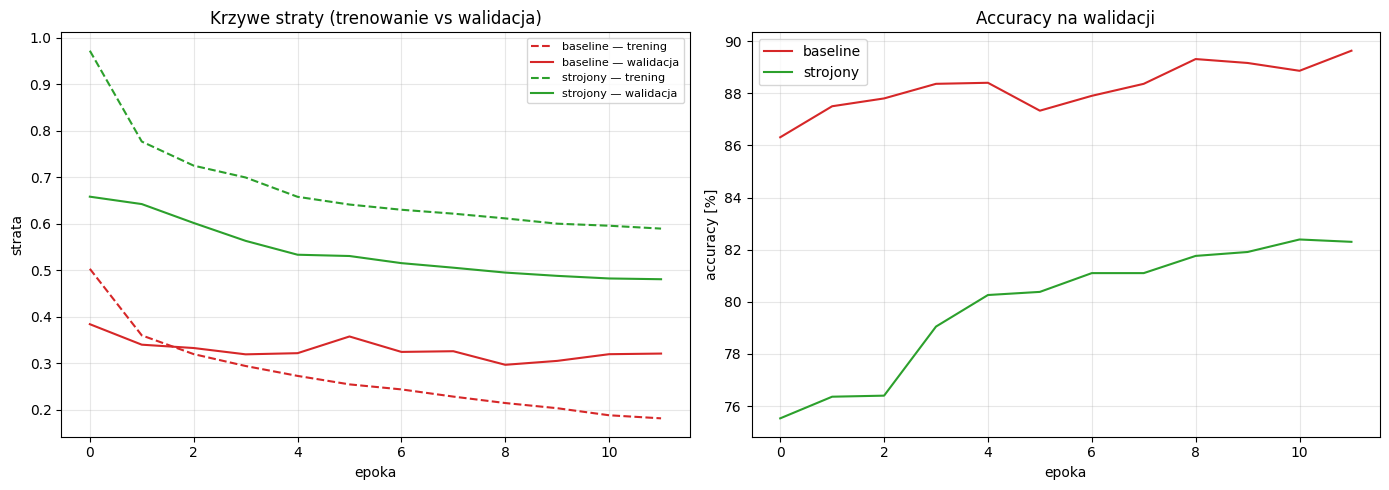

In [ ]:
EPOCHS = 12
LR = 1e-3

print("\n" + "="*70)
print("EKSPERYMENT 1: BASELINE (bez regularyzacji)")
print("="*70)
torch.manual_seed(0)
baseline = MLP(use_bn=False, p_drop=0.0)
hist_baseline = run_training(
    baseline, train_dl_plain, val_dl,
    epochs=EPOCHS, lr=LR, verbose=True
)
gap_baseline = compute_generalization_gap(baseline, train_eval_dl, val_dl)
print(f"\nLuka generalizacji (baseline): {gap_baseline:.4f}")

print("\n" + "="*70)
print("EKSPERYMENT 2a: TYLKO AUGMENTACJA")
print("="*70)
torch.manual_seed(0)
aug_only = MLP(use_bn=False, p_drop=0.0)
hist_aug = run_training(
    aug_only, train_dl_aug, val_dl,
    epochs=EPOCHS, lr=LR, verbose=True
)
gap_aug = compute_generalization_gap(aug_only, train_eval_dl, val_dl)
print(f"\nLuka generalizacji (aug_only): {gap_aug:.4f}")

print("\n" + "="*70)
print("EKSPERYMENT 2b: TYLKO BATCHNORM + DROPOUT")
print("="*70)
torch.manual_seed(0)
bn_drop = MLP(use_bn=True, p_drop=0.3)
hist_bn_drop = run_training(
    bn_drop, train_dl_plain, val_dl,
    epochs=EPOCHS, lr=LR, verbose=True
)
gap_bn_drop = compute_generalization_gap(bn_drop, train_eval_dl, val_dl)
print(f"\nLuka generalizacji (bn_drop): {gap_bn_drop:.4f}")

print("\n" + "="*70)
print("EKSPERYMENT 2c: TYLKO WEIGHT DECAY (AdamW)")
print("="*70)
torch.manual_seed(0)
wd_only = MLP(use_bn=False, p_drop=0.0)
hist_wd = run_training(
    wd_only, train_dl_plain, val_dl,
    epochs=EPOCHS, lr=LR, weight_decay=1e-2, optimizer="adamw", verbose=True
)
gap_wd = compute_generalization_gap(wd_only, train_eval_dl, val_dl)
print(f"\nLuka generalizacji (wd_only): {gap_wd:.4f}")

print("\n" + "="*70)
print("EKSPERYMENT 2d: TYLKO SCHEDULER (StepLR)")
print("="*70)
torch.manual_seed(0)
sched_only = MLP(use_bn=False, p_drop=0.0)
hist_sched = run_training(
    sched_only, train_dl_plain, val_dl,
    epochs=EPOCHS, lr=LR, use_scheduler=True, verbose=True
)
gap_sched = compute_generalization_gap(sched_only, train_eval_dl, val_dl)
print(f"\nLuka generalizacji (sched_only): {gap_sched:.4f}")

print("\n" + "="*70)
print("EKSPERYMENT 3: WARIANT STROJONY (wszystkie techniki)")
print("="*70)
torch.manual_seed(0)
tuned = MLP(use_bn=True, p_drop=0.3)
hist_tuned = run_training(
    tuned, train_dl_aug, val_dl,
    epochs=EPOCHS, lr=LR, weight_decay=1e-4,
    optimizer="adam", use_scheduler=True, verbose=True
)
gap_tuned = compute_generalization_gap(tuned, train_eval_dl, val_dl)
print(f"\nLuka generalizacji (tuned): {gap_tuned:.4f}")

print("\n" + "="*70)
print("EKSPERYMENT 4: EARLY STOPPING (wariant strojony)")
print("="*70)
torch.manual_seed(0)
tuned_es = MLP(use_bn=True, p_drop=0.3)
hist_tuned_es = run_training(
    tuned_es, train_dl_aug, val_dl,
    epochs=30, lr=LR, weight_decay=1e-4,
    optimizer="adam", use_scheduler=True, patience=5, verbose=True
)
gap_tuned_es = compute_generalization_gap(tuned_es, train_eval_dl, val_dl)
print(f"\nLuka generalizacji (tuned + ES): {gap_tuned_es:.4f}")

# Wykresy krzywych uczenia
print("\n" + "="*70)
print("WYKRESY: BASELINE vs WARIANT STROJONY")
print("="*70)
plot_learning_curves(
    [hist_baseline, hist_tuned],
    ["baseline", "strojony"],
    ["tab:red", "tab:green"]
)


## 6. Przegląd współczynnika uczenia


EKSPERYMENT 5: PRZEGLĄD LR
lr=0.1     -> accuracy 10.27%
lr=0.01    -> accuracy 87.01%
lr=0.001   -> accuracy 88.36%
lr=0.0001  -> accuracy 85.91%


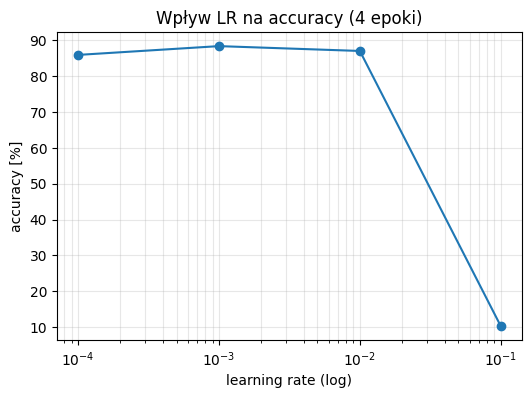

In [ ]:
print("\n" + "="*70)
print("EKSPERYMENT 5: PRZEGLĄD LR")
print("="*70)
lrs = [1e-1, 1e-2, 1e-3, 1e-4]
acc_by_lr = []

for lr in lrs:
    torch.manual_seed(0)
    m = MLP(use_bn=False, p_drop=0.0)
    h = run_training(m, train_dl_plain, val_dl, epochs=4, lr=lr, verbose=False)
    best_acc = max(h["val_acc"])
    acc_by_lr.append(best_acc)
    print(f"lr={lr:<7} -> accuracy {best_acc*100:.2f}%")

plt.figure(figsize=(6, 4))
plt.semilogx(lrs, [a*100 for a in acc_by_lr], "o-")
plt.xlabel("learning rate (log)")
plt.ylabel("accuracy [%]")
plt.title("Wpływ LR na accuracy (4 epoki)")
plt.grid(True, which="both", alpha=0.3)
plt.show()


## 7. Końcowa ewaluacja na zbiorze testowym

In [ ]:
print("\n" + "="*70)
print("KOŃCOWA EWALUACJA NA ZBIORZE TESTOWYM")
print("="*70)

# Najlepszy model (z early stopping)
test_loss, test_acc = evaluate(tuned_es, test_dl)
print(f"Najlepszy model (tuned + ES):")
print(f"  Test accuracy: {test_acc*100:.2f}%")
print(f"  Test loss: {test_loss:.4f}")

# Porównanie z baseline
test_loss_base, test_acc_base = evaluate(baseline, test_dl)
print(f"\nBaseline:")
print(f"  Test accuracy: {test_acc_base*100:.2f}%")
print(f"  Test loss: {test_loss_base:.4f}")

print("\n" + "="*70)
print("PODSUMOWANIE")
print("="*70)
print(f"Baseline accuracy (val): {max(hist_baseline['val_acc'])*100:.2f}%")
print(f"Tuned+ES accuracy (val): {max(hist_tuned_es['val_acc'])*100:.2f}%")
print(f"Poprawa: {(max(hist_tuned_es['val_acc']) - max(hist_baseline['val_acc']))*100:.2f} p.p.")


KOŃCOWA EWALUACJA NA ZBIORZE TESTOWYM
Najlepszy model (tuned + ES):
  Test accuracy: 84.22%
  Test loss: 0.4293

Baseline:
  Test accuracy: 88.30%
  Test loss: 0.3791

PODSUMOWANIE
Baseline accuracy (val): 89.63%
Tuned+ES accuracy (val): 84.71%
Poprawa: -4.92 p.p.
